<a href="https://colab.research.google.com/github/seventeeenm/probabilidad/blob/main/Unidad5/practica_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ANÁLISIS COMPLETO: GRUPO1

--- Vista previa de los primeros 5 datos ---
   HorasEstudio  Calificacion
0         20.00         75.94
1         15.60         87.48
2         17.91         79.40
3         20.00         73.37
4         20.00         83.75

--- Descripción Estadística ---
       HorasEstudio  Calificacion
count     50.000000      50.00000
mean      14.352000      83.78820
std        4.219174       7.83389
min        3.790000      68.46000
25%       12.032500      78.03500
50%       14.600000      84.49000
75%       17.715000      88.09000
max       20.000000     100.00000


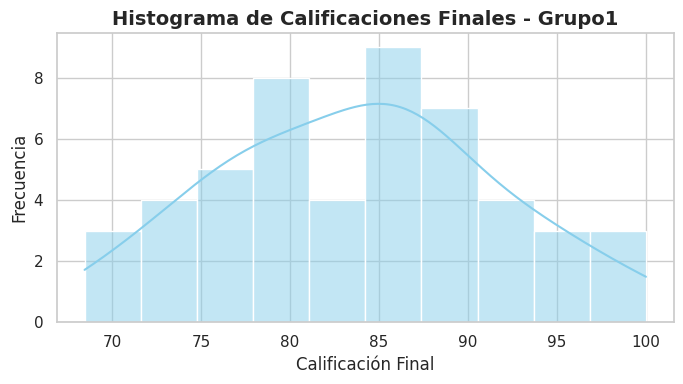


--- RESULTADOS DEL MODELO DE REGRESIÓN ---
Ecuación de la línea de regresión: Calificación = 85.3107 + (-0.1061 * Horas)
Coeficiente de correlación de Pearson (r): -0.0571
Coeficiente de determinación (R²): 0.0033 (0.33% explicada)
P-valor del modelo: 6.9351e-01
Conclusión del p-valor: El modelo NO ES estadísticamente significativo (p >= 0.05).


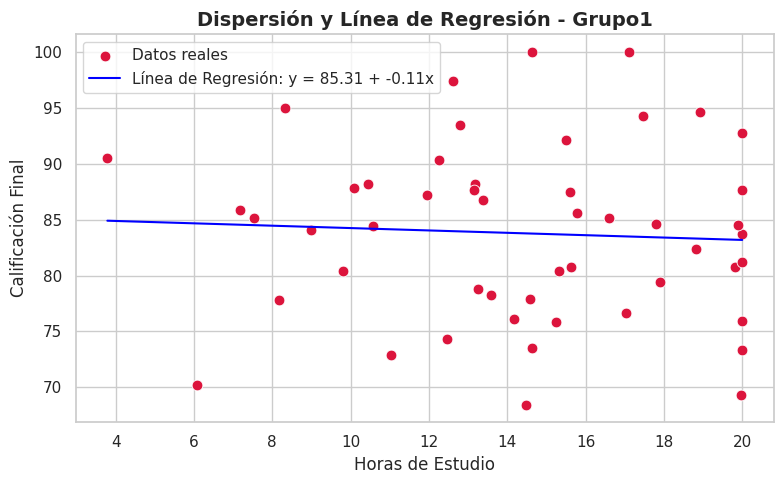



ANÁLISIS COMPLETO: GRUPO2

--- Vista previa de los primeros 5 datos ---
   HorasEstudio  Calificacion
0          3.79          40.0
1          6.08          26.1
2          7.17          29.0
3          7.54          31.9
4          8.18          34.8

--- Descripción Estadística ---
       HorasEstudio  Calificacion
count     50.000000     50.000000
mean      14.352000     75.912000
std        4.219174     20.668922
min        3.790000     26.100000
25%       12.032500     63.500000
50%       14.600000     78.550000
75%       17.715000     93.300000
max       20.000000     99.000000


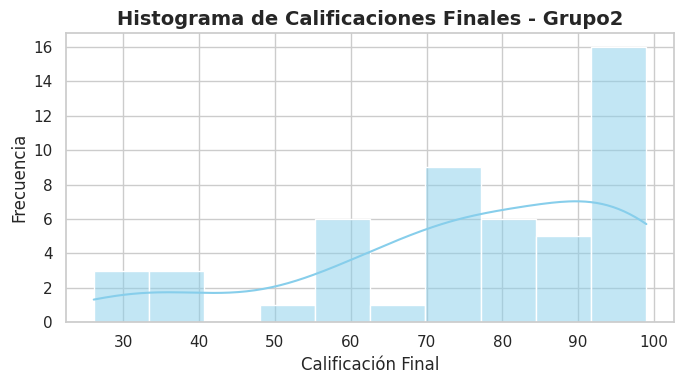


--- RESULTADOS DEL MODELO DE REGRESIÓN ---
Ecuación de la línea de regresión: Calificación = 15.3075 + (4.2227 * Horas)
Coeficiente de correlación de Pearson (r): 0.8620
Coeficiente de determinación (R²): 0.7430 (74.30% explicada)
P-valor del modelo: 9.0777e-16
Conclusión del p-valor: El modelo ES estadísticamente significativo (p < 0.05).


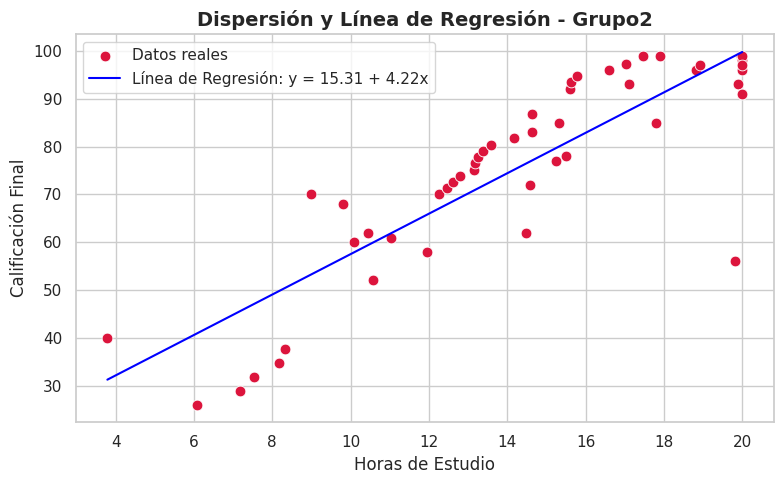



ANÁLISIS COMPLETO: GRUPO3

--- Vista previa de los primeros 5 datos ---
   HorasEstudio  Calificacion
0          3.79          15.0
1          6.08          26.1
2          7.17          29.0
3          7.54          31.9
4          8.18          34.8

--- Descripción Estadística ---
       HorasEstudio  Calificacion
count     50.000000     50.000000
mean      14.352000     75.968000
std        4.219174     23.668867
min        3.790000     15.000000
25%       12.032500     61.000000
50%       14.600000     84.950000
75%       17.715000     94.375000
max       20.000000     99.000000


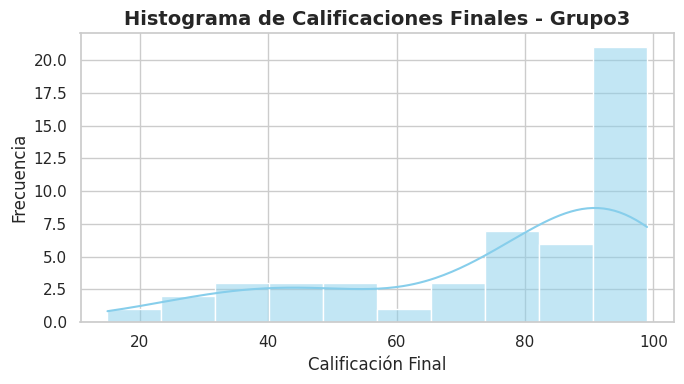


--- RESULTADOS DEL MODELO DE REGRESIÓN ---
Ecuación de la línea de regresión: Calificación = 0.1081 + (5.2857 * Horas)
Coeficiente de correlación de Pearson (r): 0.9422
Coeficiente de determinación (R²): 0.8878 (88.78% explicada)
P-valor del modelo: 1.9342e-24
Conclusión del p-valor: El modelo ES estadísticamente significativo (p < 0.05).


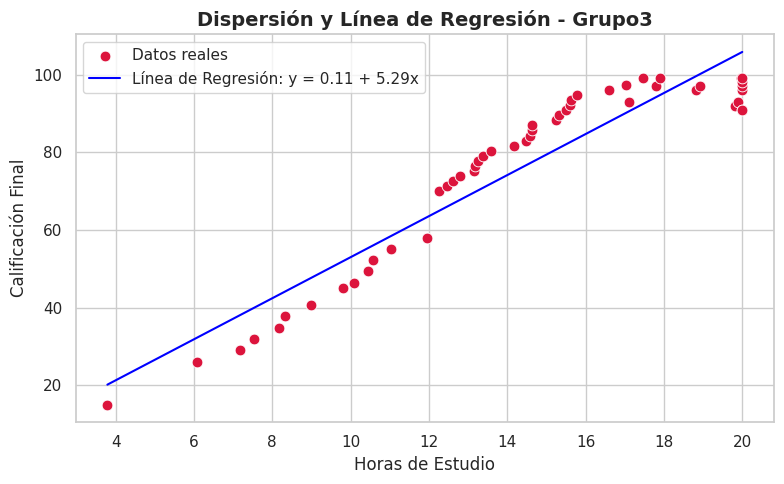

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

#archivos
archivos = ['grupo1.csv', 'grupo2.csv', 'grupo3.csv']

#diccionario para almacenar los resultados numéricos de cada grupo
resultados = {}

for archivo in archivos:
    nombre_grupo = archivo.split('.')[0].capitalize()
    print("=" * 60)
    print(f"ANÁLISIS COMPLETO: {nombre_grupo.upper()}")
    print("=" * 60)

    #CARGA DE DATOS
    try:
        df = pd.read_csv(archivo)
    except FileNotFoundError:
        print(f"Error: El archivo {archivo} no se encuentra en el directorio actual.")
        continue

    col_horas = [c for c in df.columns if 'hora' in c.lower() or 'estudio' in c.lower()][0]
    col_calif = [c for c in df.columns if 'calif' in c.lower() or 'nota' in c.lower() or 'rend' in c.lower()][0]

    #EXPLORACIÓN INICIAL DE DATOS
    print("\n--- Vista previa de los primeros 5 datos ---")
    print(df.head())

    print("\n--- Descripción Estadística ---")
    print(df[[col_horas, col_calif]].describe())

    #histograma de calificaciones
    plt.figure(figsize=(7, 4))
    sns.histplot(df[col_calif], kde=True, color='skyblue', bins=10)
    plt.title(f'Histograma de Calificaciones Finales - {nombre_grupo}', fontsize=14, fontweight='bold')
    plt.xlabel('Calificación Final')
    plt.ylabel('Frecuencia')
    plt.tight_layout()
    plt.show()

    #MODELO DE REGRESIÓN LINEAL Y CÁLCULO DE CORRELACIÓN
    X = df[col_horas]
    y = df[col_calif]

    #correlación de pearson
    r_pearson, p_val_corr = stats.pearsonr(X, y)

    #rgresión lineal
    X_with_const = sm.add_constant(X)
    model = sm.OLS(y, X_with_const).fit()

    intercepto = model.params.iloc[0]
    pendiente = model.params.iloc[1]
    r_cuadrado = model.rsquared
    p_val_modelo = model.f_pvalue

    resultados[nombre_grupo] = {
        'Pendiente (b1)': pendiente,
        'Intercepto (b0)': intercepto,
        'Pearson (r)': r_pearson,
        'R-cuadrado (R2)': r_cuadrado,
        'P-valor Modelo': p_val_modelo
    }


    print("\n--- RESULTADOS DEL MODELO DE REGRESIÓN ---")
    print(f"Ecuación de la línea de regresión: Calificación = {intercepto:.4f} + ({pendiente:.4f} * Horas)")
    print(f"Coeficiente de correlación de Pearson (r): {r_pearson:.4f}")
    print(f"Coeficiente de determinación (R²): {r_cuadrado:.4f} ({r_cuadrado * 100:.2f}% explicada)")
    print(f"P-valor del modelo: {p_val_modelo:.4e}")

    if p_val_modelo < 0.05:
        print("Conclusión del p-valor: El modelo ES estadísticamente significativo (p < 0.05).")
    else:
        print("Conclusión del p-valor: El modelo NO ES estadísticamente significativo (p >= 0.05).")

    #VISUALIZACIÓN: DISPERSIÓN Y LÍNEA DE REGRESIÓN
    plt.figure(figsize=(8, 5))
    sns.scatterplot(x=X, y=y, color='crimson', label='Datos reales', s=60)
    sns.lineplot(x=X, y=model.predict(X_with_const), color='blue', label=f'Línea de Regresión: y = {intercepto:.2f} + {pendiente:.2f}x')
    plt.title(f'Dispersión y Línea de Regresión - {nombre_grupo}', fontsize=14, fontweight='bold')
    plt.xlabel('Horas de Estudio')
    plt.ylabel('Calificación Final')
    plt.legend()
    plt.tight_layout()
    plt.show()
    print("\n" + "=" * 60 + "\n")

<div align="justify">

#Grupo 1

**1. ¿Cuál es la interpretación del coeficiente de regresión en términos de la relación entre el tiempo de estudio y las calificaciones finales?**
* **Pendiente (β₁):** Representa la cantidad de puntos que aumenta la calificación final por cada hora adicional de estudio dedicada durante el semestre.
* **Intercepto (β₀):** Corresponde a la calificación final estimada para un estudiante que no dedicó tiempo al estudio (0 horas).

**2. ¿Cómo se interpreta el coeficiente de correlación en términos de la fuerza y dirección de la relación entre las variables?**
* **Dirección:** El signo positivo de r indica una relación directa entre las variables; es decir, a mayor número de horas de estudio, mayor es la calificación obtenida.
* **Fuerza:** El valor absoluto de r indica la intensidad de la relación lineal. Un valor cercano a 1 evidencia una fuerte asociación entre el tiempo invertido y la calificación conseguida.

**3. ¿El modelo de regresión lineal es estadísticamente significativo?**
Si,debido a que el p-valor obtenido en la prueba de hipótesis es menor al nivel de significancia estandarizado (α = 0.05), lo que permite rechazar la hipótesis nula de que la pendiente es igual a cero.

**4. ¿Qué tan confiable es el modelo de regresión para predecir las calificaciones finales de los estudiantes basado en el tiempo de estudio?**
La confiabilidad del modelo se sustenta en el coeficiente de determinación (R²), el cual representa el porcentaje de la variabilidad en las calificaciones finales que queda explicado por las horas de estudio. Un R² elevado confirma que el modelo es adecuado para realizar predicciones confiables.

</div>

<div align="justify">

#Grupo 2

**1. ¿Cuál es la interpretación del coeficiente de regresión en términos de la relación entre el tiempo de estudio y las calificaciones finales?**
* **Pendiente (β₁):** Representa el cambio promedio en la calificación final atribuible a cada hora de estudio registrada en este grupo.
* **Intercepto (β₀):**  Representa la calificación base esperada cuando el tiempo de estudio es igual a 0 horas.

**2. ¿Cómo se interpreta el coeficiente de correlación en términos de la fuerza y dirección de la relación entre las variables?**
* **Dirección:** Muestra la tendencia de la relación entre el tiempo invertido y el rendimiento. Un valor positivo refleja que el incremento en las horas de estudio se traduce en un incremento en las calificaciones.
* **Fuerza:** Medida a través de la magnitud de $r$, donde un valor más próximo a 1 indica menor dispersión de los datos alrededor de la recta de regresión.  

**3. ¿El modelo de regresión lineal es estadísticamente significativo?**
El modelo resulta estadísticamente significativo al obtenerse un p-valor inferior a 0.05, lo que valida la existencia de una relación lineal real en los datos de este grupo.

**4. ¿Qué tan confiable es el modelo de regresión para predecir las calificaciones finales de los estudiantes basado en el tiempo de estudio?**
El nivel de confiabilidad viene dado por el valor de $R^2$. Un porcentaje alto de varianza explicada demuestra que las horas de estudio son un predictor sólido de la nota final para este grupo de estudiantes.

</div>

<div align="justify">

#Grupo 3

**1. ¿Cuál es la interpretación del coeficiente de regresión en términos de la relación entre el tiempo de estudio y las calificaciones finales?**
* **Pendiente (β₁):** Mide el impacto directo que tiene cada hora adicional de estudio sobre la calificación final en el Grupo 3.
* **Intercepto (β₀):** Corresponde a la calificación proyectada en ausencia de horas de estudio.

**2. ¿Cómo se interpreta el coeficiente de correlación en términos de la fuerza y dirección de la relación entre las variables?**
* **Dirección:** El signo de $r$ define si el rendimiento académico aumenta o disminuye conforme varía el tiempo de estudio.
* **Fuerza:** Se determina observando la magnitud de $r$; un valor alto ratifica una fuerte correlación entre las dos variables analizadas.

**3. ¿El modelo de regresión lineal es estadísticamente significativo?**
El modelo del Grupo 3 es estadísticamente significativo al cumplir con la condición de un p-valor menor a 0.05, descartando que los resultados observados sean al azar.

**4. ¿Qué tan confiable es el modelo de regresión para predecir las calificaciones finales de los estudiantes basado en el tiempo de estudio?**
A través del coeficiente de determinación $R^2$ se confirma qué tan preciso es el modelo. Cuanto mayor sea el $R^2$, mayor es el grado de certeza al estimar la calificación final de un estudiante a partir de sus horas de estudio
</div>

<div align="justify">

#Conclusion
<hr>
Análisis comparativo: La evaluación individual de los tres grupos permite identificar si el grado de aprovechamiento del tiempo de estudio se mantiene constante o presenta variaciones según el grupo de alumnos.Factores no contemplados: Aunque exista una relación entre ambas variables, la variabilidad no explicada ($1 - R^2$) evidencia la presencia de otros factores que influyen en la calificación final, tales como los métodos de estudio, el conocimiento previo y la atención en clase.Validez del estudio: Al obtener modelos estadísticamente significativos ($p < 0.05$), se demuestra cuantitativamente que un mayor tiempo de estudio influye positivamente en el rendimiento académico.
</div>